# Classifying and Understanding Serious Adverse Reactions to NSAIDs in Dogs and Cats
QM 640 Data Analytics Capstone, Harshit Saluja. Data: openFDA Animal and Veterinary Adverse Event Reports (2015–2025).

Run with **Runtime → Run all**. The notebook downloads the data directly from the FDA, cleans it, runs the EDA, answers RQ1–RQ4, and saves all figures and result tables.

### Downloading the FDA Data

In [1]:
import requests, time, json

url = "https://api.fda.gov/animalandveterinary/event.json"
species_list = ["Dog", "Cat"]
drugs = ["Carprofen", "Meloxicam", "Grapiprant", "Deracoxib", "Firocoxib", "Robenacoxib"]
records = []

for species in species_list:
    for drug in drugs:
        for year in range(2015, 2026):
            search = (f'animal.species:"{species}" AND drug.active_ingredients.name:"{drug}" '
                      f'AND original_receive_date:[{year}0101 TO {year}1231]')
            skip, got = 0, 0
            while True:
                r = requests.get(url, params={"search": search, "limit": 1000, "skip": skip})
                if r.status_code == 404:          # no reports for this combination
                    break
                if r.status_code == 429:          # asked too fast: wait and retry
                    time.sleep(10); continue
                data = r.json()
                records += data["results"]
                got += len(data["results"])
                skip += 1000
                time.sleep(0.3)
                if skip >= data["meta"]["results"]["total"]:
                    break
            print(f"{species} {drug} {year}: {got}")

json.dump(records, open("raw_reports.json", "w"))
print("\nTOTAL downloaded:", len(records))

Dog Carprofen 2015: 1286
Dog Carprofen 2016: 1338
Dog Carprofen 2017: 1218
Dog Carprofen 2018: 1051
Dog Carprofen 2019: 920
Dog Carprofen 2020: 922
Dog Carprofen 2021: 841
Dog Carprofen 2022: 825
Dog Carprofen 2023: 1006
Dog Carprofen 2024: 2031
Dog Carprofen 2025: 1998
Dog Meloxicam 2015: 332
Dog Meloxicam 2016: 352
Dog Meloxicam 2017: 352
Dog Meloxicam 2018: 276
Dog Meloxicam 2019: 260
Dog Meloxicam 2020: 235
Dog Meloxicam 2021: 194
Dog Meloxicam 2022: 196
Dog Meloxicam 2023: 206
Dog Meloxicam 2024: 377
Dog Meloxicam 2025: 367
Dog Grapiprant 2015: 1
Dog Grapiprant 2016: 0
Dog Grapiprant 2017: 1241
Dog Grapiprant 2018: 1197
Dog Grapiprant 2019: 968
Dog Grapiprant 2020: 791
Dog Grapiprant 2021: 547
Dog Grapiprant 2022: 549
Dog Grapiprant 2023: 544
Dog Grapiprant 2024: 732
Dog Grapiprant 2025: 811
Dog Deracoxib 2015: 286
Dog Deracoxib 2016: 248
Dog Deracoxib 2017: 378
Dog Deracoxib 2018: 248
Dog Deracoxib 2019: 184
Dog Deracoxib 2020: 165
Dog Deracoxib 2021: 122
Dog Deracoxib 2022: 71
D

### Cleaning the Data

In [2]:
cleaning_log = []
def log(step, n):
    cleaning_log.append((step, n))
    print(f"{step:<45} {n:>6}")

log("Raw reports downloaded", len(records))

# 1. Remove duplicates (same report ID downloaded twice)
unique = {}
for r in records:
    unique[r["unique_aer_id_number"]] = r
reports = list(unique.values())
log("After removing duplicates", len(reports))

# 2. Keep reports that mention exactly ONE of our six NSAIDs
def nsaids_in(report):
    found = set()
    for d in report.get("drug", []):
        for ingredient in d.get("active_ingredients", []):
            name = ingredient.get("name", "").lower()
            for drug in drugs:
                if drug.lower() in name:
                    found.add(drug)
    return found

reports = [r for r in reports if len(nsaids_in(r)) == 1]
log("After keeping exactly one NSAID", len(reports))

# 3. Keep reports about a single animal
def one_animal(report):
    n = report.get("number_of_animals_affected")
    return n is None or float(n) <= 1

reports = [r for r in reports if one_animal(r)]
log("After keeping single-animal reports", len(reports))

Raw reports downloaded                         31666
After removing duplicates                      30616
After keeping exactly one NSAID                29595
After keeping single-animal reports            29219


### Putting the Data into Table

In [3]:
import pandas as pd

age_to_years = {"year": 1, "month": 1/12, "week": 1/52.18, "day": 1/365.25, "hour": 1/8766}
weight_to_kg = {"kilogram": 1, "pound": 0.4536, "gram": 0.001, "ounce": 0.02835}

def convert(block, table):
    try:
        value = float(block["min"])
        unit = block["unit"].strip().lower().rstrip("s")
        return value * table[unit]
    except (KeyError, TypeError, ValueError, AttributeError):
        return None

reaction_groups = {
    "gi": ["vomit", "diarrh", "gastro", "melena", "melaena", "anorexia", "inappetence", "ulcer"],
    "renal": ["renal", "kidney", "azotem", "azotaem", "creatinine", "urea", "polyuria", "polydipsia"],
    "hepatic": ["hepat", "liver", "jaundice", "icterus", "bilirubin", "alanine"],
    "neuro": ["seizure", "convuls", "ataxia", "tremor", "neurolog", "collapse"],
}

rows = []
for r in reports:
    animal = r.get("animal", {})
    terms = [x.get("veddra_term_name", "").lower() for x in r.get("reaction", [])]
    row = {
        "report_id": r.get("unique_aer_id_number"),
        "receive_date": r.get("original_receive_date"),
        "serious": 1 if str(r.get("serious_ae")).lower() == "true" else 0,
        "species": animal.get("species"),
        "drug": nsaids_in(r).pop(),
        "age_years": convert(animal.get("age"), age_to_years),
        "weight_kg": convert(animal.get("weight"), weight_to_kg),
        "sex": animal.get("gender"),
        "repro_status": animal.get("reproductive_status"),
        "breed": str(animal.get("breed", {}).get("breed_component")),
        "route": r.get("drug", [{}])[0].get("route"),
        "reporter": r.get("primary_reporter"),
        "outcome": "; ".join(o.get("medical_status", "") for o in r.get("outcome", [])),
    }
    for group, words in reaction_groups.items():
        row["rx_" + group] = int(any(w in t for t in terms for w in words))
    rows.append(row)

df = pd.DataFrame(rows)
print("Rows, columns:", df.shape)
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1))
df.head()

Rows, columns: (29219, 17)

Missing values (%):
report_id       0.0
receive_date    0.0
serious         0.0
species         0.0
drug            0.0
age_years       5.4
weight_kg       7.1
sex             0.1
repro_status    0.8
breed           0.0
route           0.9
reporter        0.0
outcome         0.0
rx_gi           0.0
rx_renal        0.0
rx_hepatic      0.0
rx_neuro        0.0
dtype: float64


,report_id,receive_date,serious,species,drug,age_years,weight_kg,sex,repro_status,breed,route,reporter,outcome,rx_gi,rx_renal,rx_hepatic,rx_neuro
0,USA-USFDACVM-2015-US-406754,20150722,0,Dog,Carprofen,15.0,39.010,Male,Neutered,Terrier - Bull - American Pit,Oral,Other,Recovered/Normal,0,0,0,0
1,USA-USFDACVM-2015-US-416509,20151215,1,Dog,Carprofen,4.0,36.287,Female,Neutered,Retriever - Labrador,Oral,Veterinarian,Euthanized,1,0,1,1
2,USA-USFDACVM-2015-US-405966,20151006,1,Dog,Carprofen,12.0,10.500,Male,Neutered,Bichon Frise,Subcutaneous,Veterinarian,Ongoing,0,0,0,0
3,USA-USFDACVM-2015-US-379542,20150518,0,Dog,Carprofen,16.0,22.680,Male,Neutered,Retriever - Labrador,Oral,Other,Recovered/Normal,0,0,0,0
4,USA-USFDACVM-2015-US-192780,20150123,0,Dog,Carprofen,11.0,36.470,Female,Neutered,Retriever - Labrador,Oral,Veterinarian,Ongoing,1,0,1,0


### Outlier Handling

In [4]:
# Some reports store values as lists; count them, then keep one value per cell
list_dates = int(df["receive_date"].apply(lambda v: isinstance(v, list)).sum())
for col in df.columns:
    if col == "receive_date":
        df[col] = df[col].apply(lambda v: v[0] if isinstance(v, list) and v else v)
    else:
        df[col] = df[col].apply(lambda v: "; ".join(map(str, v)) if isinstance(v, list) else v)
print("Reports whose date was stored as a list:", list_dates)

# Convert the date text (e.g. 20150326) into a real date
df["receive_date"] = pd.to_datetime(df["receive_date"], format="%Y%m%d", errors="coerce")
print("Dates that could not be read:", int(df["receive_date"].isna().sum()))

# Find impossible ages and weights, and blank them out
max_age = df["species"].map({"Dog": 25, "Cat": 30})
max_weight = df["species"].map({"Dog": 100, "Cat": 15})

bad_age = (df["age_years"] <= 0) | (df["age_years"] > max_age)
bad_weight = (df["weight_kg"] <= 0) | (df["weight_kg"] > max_weight)
df.loc[bad_age, "age_years"] = None
df.loc[bad_weight, "weight_kg"] = None

log("Impossible ages set to missing", int(bad_age.sum()))
log("Impossible weights set to missing", int(bad_weight.sum()))
log("FINAL clean reports", len(df))
log("Reports with both age and weight (RQ3)", int(df[["age_years", "weight_kg"]].notna().all(axis=1).sum()))
log("Serious reports", int(df["serious"].sum()))
print(f"\nShare serious: {df['serious'].mean():.1%}")

# Save both files and download them to your computer
df.to_csv("nsaid_reports_clean.csv", index=False)
pd.DataFrame(cleaning_log, columns=["step", "reports"]).to_csv("cleaning_log.csv", index=False)

from google.colab import files
files.download("nsaid_reports_clean.csv")
files.download("cleaning_log.csv")

Reports whose date was stored as a list: 1
Dates that could not be read: 0
Impossible ages set to missing                     1
Impossible weights set to missing                 11
FINAL clean reports                            29219
Reports with both age and weight (RQ3)         26712
Serious reports                                14197

Share serious: 48.6%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### EDA

In [5]:
print("=== Reports and % serious by species and drug ===")
table = df.groupby(["species", "drug"])["serious"].agg(reports="count", serious_pct="mean")
table["serious_pct"] = (table["serious_pct"] * 100).round(1)
print(table.sort_values("reports", ascending=False))

print("\n=== Age (years) and weight (kg) by species ===")
print(df.groupby("species")[["age_years", "weight_kg"]].describe().round(1).T)

=== Reports and % serious by species and drug ===
                     reports  serious_pct
species drug                             
Dog     Carprofen      12648         54.9
        Grapiprant      6520         30.0
        Meloxicam       2883         53.0
Cat     Robenacoxib     2568         43.5
Dog     Firocoxib       1734         58.5
        Deracoxib       1700         56.5
Cat     Meloxicam        958         61.5
Dog     Robenacoxib      101         33.7
Cat     Carprofen         80         56.2
        Firocoxib         15         53.3
        Grapiprant         9         11.1
        Deracoxib          3         66.7

=== Age (years) and weight (kg) by species ===
species             Cat      Dog
age_years count  3438.0  24214.0
          mean      6.5      8.9
          std       5.2      4.3
          min       0.1      0.0
          25%       1.1      6.0
          50%       6.0     10.0
          75%      11.0     12.0
          max      25.0     20.0
weight_kg count  

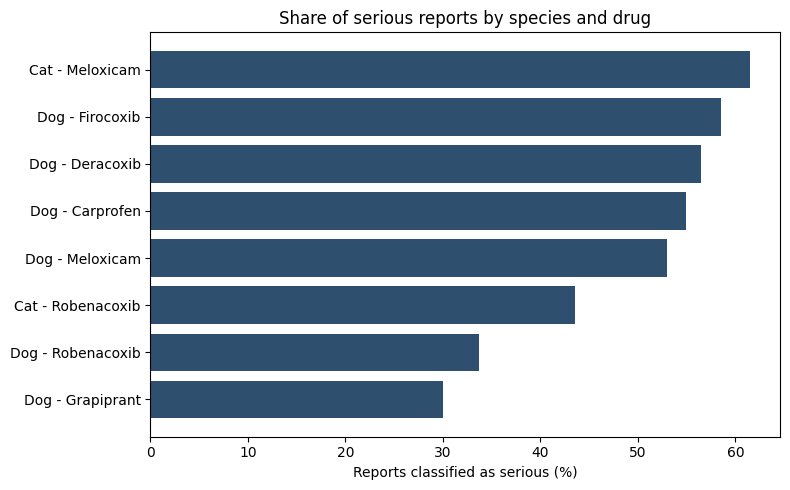

           reports  serious_pct
age_years                      
<1            2595         49.0
1-3           2336         50.7
3-6           3408         52.7
6-9           5384         52.3
9-12          7751         48.3
12-15         5301         46.3
15+            877         47.1


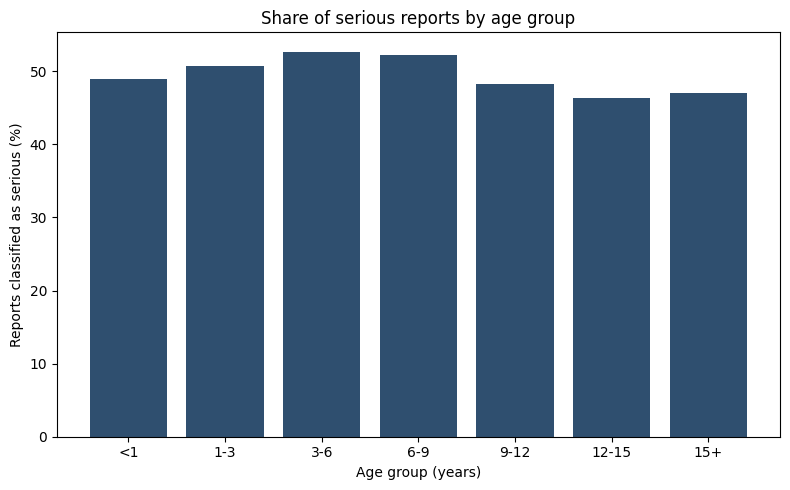

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 800x500 with 0 Axes>

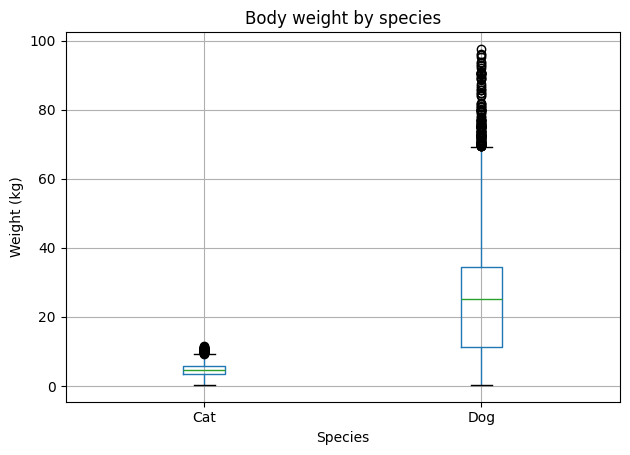

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import matplotlib.pyplot as plt

# Chart 1: % serious by drug and species (groups with 100+ reports)
big = table[table["reports"] >= 100].reset_index()
big["label"] = big["species"] + " - " + big["drug"]
big = big.sort_values("serious_pct")
plt.figure(figsize=(8, 5))
plt.barh(big["label"], big["serious_pct"], color="#2F4F6F")
plt.xlabel("Reports classified as serious (%)")
plt.title("Share of serious reports by species and drug")
plt.tight_layout()
plt.savefig("fig_serious_by_drug.png", dpi=200)
plt.show()

# Chart 2: age of serious vs non-serious reports
# Put ages into groups, then show % serious in each group
bands = pd.cut(df["age_years"], bins=[0, 1, 3, 6, 9, 12, 15, 30],
               labels=["<1", "1-3", "3-6", "6-9", "9-12", "12-15", "15+"])
by_age = df.groupby(bands, observed=True)["serious"].agg(reports="count", serious_pct="mean")
by_age["serious_pct"] = (by_age["serious_pct"] * 100).round(1)
print(by_age)

plt.figure(figsize=(8, 5))
plt.bar(by_age.index.astype(str), by_age["serious_pct"], color="#2F4F6F")
plt.xlabel("Age group (years)")
plt.ylabel("Reports classified as serious (%)")
plt.title("Share of serious reports by age group")
plt.tight_layout()
plt.savefig("fig_serious_by_age.png", dpi=200)
plt.show()
files.download("fig_serious_by_age.png")

# Chart 3: weight by species
plt.figure(figsize=(8, 5))
df.boxplot(column="weight_kg", by="species")
plt.suptitle(""); plt.title("Body weight by species")
plt.xlabel("Species"); plt.ylabel("Weight (kg)")
plt.tight_layout()
plt.savefig("fig_weight_by_species.png", dpi=200)
plt.show()

for f in ["fig_serious_by_drug.png", "fig_serious_by_age.png", "fig_weight_by_species.png"]:
    files.download(f)

## RQ1

In [7]:
from scipy.stats import chi2_contingency
import numpy as np

# Keep only meloxicam reports
mel = df[df["drug"] == "Meloxicam"]

# The 2 x 2 table: species vs serious
counts = pd.crosstab(mel["species"], mel["serious"])
counts.columns = ["Not serious", "Serious"]
print("Counts:\n", counts, "\n")

# Chi-square test
chi2, p, dof, expected = chi2_contingency(counts, correction=False)

# Proportions, difference, 95% CI, effect size
n_cat, n_dog = counts.loc["Cat"].sum(), counts.loc["Dog"].sum()
p_cat = counts.loc["Cat", "Serious"] / n_cat
p_dog = counts.loc["Dog", "Serious"] / n_dog
diff = p_cat - p_dog
se = np.sqrt(p_cat * (1 - p_cat) / n_cat + p_dog * (1 - p_dog) / n_dog)
phi = np.sqrt(chi2 / (n_cat + n_dog))

print(f"Cats serious: {p_cat:.1%}   Dogs serious: {p_dog:.1%}")
print(f"Difference: {diff*100:.1f} points (95% CI {(diff-1.96*se)*100:.1f} to {(diff+1.96*se)*100:.1f})")
print(f"Chi-square = {chi2:.2f},  p-value = {p:.6f},  phi = {phi:.3f}")
print("Decision:", "Reject H0 (real difference)" if p < 0.05 else "Cannot reject H0 (could be luck)")

Counts:
          Not serious  Serious
species                      
Cat              369      589
Dog             1356     1527 

Cats serious: 61.5%   Dogs serious: 53.0%
Difference: 8.5 points (95% CI 4.9 to 12.1)
Chi-square = 21.08,  p-value = 0.000004,  phi = 0.074
Decision: Reject H0 (real difference)


Among meloxicam reports, a higher proportion of cat reports (61.5%, n = 958) than dog reports (53.0%, n = 2,883) were classified as serious, χ²(1, N = 3,841) = 21.08, p < .001, φ = 0.07. The difference of 8.5 percentage points (95% CI [4.9, 12.1]) was statistically significant but small. These figures describe reported cases and do not establish that meloxicam carries a higher risk for cats.

## RQ2

In [8]:
# Keep only dog reports for grapiprant and carprofen
rq2 = df[(df["species"] == "Dog") & (df["drug"].isin(["Grapiprant", "Carprofen"]))]

counts = pd.crosstab(rq2["drug"], rq2["serious"])
counts.columns = ["Not serious", "Serious"]
print("Counts:\n", counts, "\n")

chi2, p, dof, expected = chi2_contingency(counts, correction=False)

n_g, n_c = counts.loc["Grapiprant"].sum(), counts.loc["Carprofen"].sum()
p_g = counts.loc["Grapiprant", "Serious"] / n_g
p_c = counts.loc["Carprofen", "Serious"] / n_c
diff = p_g - p_c
se = np.sqrt(p_g * (1 - p_g) / n_g + p_c * (1 - p_c) / n_c)
phi = np.sqrt(chi2 / (n_g + n_c))

print(f"Grapiprant serious: {p_g:.1%}   Carprofen serious: {p_c:.1%}")
print(f"Difference: {diff*100:.1f} points (95% CI {(diff-1.96*se)*100:.1f} to {(diff+1.96*se)*100:.1f})")
print(f"Chi-square = {chi2:.2f},  p-value = {p:.2e},  phi = {phi:.3f}")
print("Decision:", "Reject H0 (real difference)" if p < 0.05 else "Cannot reject H0 (could be luck)")

Counts:
             Not serious  Serious
drug                            
Carprofen          5705     6943
Grapiprant         4566     1954 

Grapiprant serious: 30.0%   Carprofen serious: 54.9%
Difference: -24.9 points (95% CI -26.3 to -23.5)
Chi-square = 1074.61,  p-value = 1.09e-235,  phi = 0.237
Decision: Reject H0 (real difference)


Among dog reports, a lower proportion of grapiprant reports (30.0%, n = 6,520) than carprofen reports (54.9%, n = 12,648) were classified as serious, χ²(1, N = 19,168) = 1,074.61, p < .001, φ = 0.24. The difference of 24.9 percentage points (95% CI [23.5, 26.3]) was statistically significant and small-to-medium in size. Because the data contain only reported events, this difference may also reflect differences in the dogs treated or in reporting patterns, and does not establish that grapiprant is safer.

## RQ3

In [9]:
import statsmodels.formula.api as smf

# Keep reports with both age and weight (complete cases)
rq3 = df.dropna(subset=["age_years", "weight_kg"])
print("Reports used:", len(rq3))

# Logistic regression; carprofen is the comparison drug, dog is the comparison species
model = smf.logit("serious ~ age_years + weight_kg + C(species, Treatment('Dog')) "
                  "+ C(drug, Treatment('Carprofen'))", data=rq3).fit(disp=0)

# Turn coefficients (b) into odds ratios with 95% CI and p-values
results = pd.DataFrame({
    "b": model.params,
    "SE": model.bse,
    "odds_ratio": np.exp(model.params),
    "CI_low": np.exp(model.conf_int()[0]),
    "CI_high": np.exp(model.conf_int()[1]),
    "p_value": model.pvalues,
}).round(4)
print(results.loc[["age_years", "weight_kg"]])

# Same effect per one standard deviation (matches the synopsis sample size)
for v in ["age_years", "weight_kg"]:
    sd = rq3[v].std()
    print(f"{v}: SD = {sd:.1f}, odds ratio per SD = {np.exp(model.params[v] * sd):.3f}")

Reports used: 26712
                b      SE  odds_ratio  CI_low  CI_high  p_value
age_years  0.0085  0.0029      1.0085  1.0028   1.0143   0.0037
weight_kg  0.0022  0.0009      1.0022  1.0004   1.0041   0.0183
age_years: SD = 4.5, odds ratio per SD = 1.039
weight_kg: SD = 15.1, odds ratio per SD = 1.034


After adjusting for species and NSAID, both age and body weight were positively associated with the odds of a report being classified as serious (age: OR = 1.008 per year, 95% CI [1.003, 1.014], p = .004; weight: OR = 1.002 per kg, 95% CI [1.000, 1.004], p = .018). Per standard deviation, the odds increased by about 4% for age and 3% for weight, well below the odds ratio of 1.20 defined in the synopsis as the smallest effect of interest. The associations are statistically significant but of limited practical importance.

## RQ4

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

# Sort by report ID so the random 80/20 split is identical on every run
df = df.sort_values("report_id").reset_index(drop=True)

# Group breeds: keep the 15 most common, the rest become "Other"
top_breeds = df["breed"].value_counts().head(15).index
df["breed_group"] = df["breed"].where(df["breed"].isin(top_breeds), "Other")

numeric = ["age_years", "weight_kg"]
categorical = ["species", "drug", "sex", "repro_status", "breed_group", "route", "reporter"]
flags = ["rx_gi", "rx_renal", "rx_hepatic", "rx_neuro"]
X = df[numeric + categorical + flags]
y = df["serious"]

# 80% train / 20% test, keeping the same share of serious reports in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Training reports:", len(X_train), "  Test reports:", len(X_test))

# Prepare columns: fill gaps, scale numbers, turn categories into 0/1 columns
prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), numeric),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value="Unknown")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ("flag", "passthrough", flags),
])
baseline = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])

# 3-fold cross-validation on the training set, using the same folds as the tuned models
# (RandomizedSearchCV with cv=3 uses an unshuffled StratifiedKFold with 3 splits)
cv = StratifiedKFold(n_splits=3)
cv_auc = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Cross-validation AUC: {cv_auc.mean():.3f} (± {cv_auc.std():.3f})")

# Train on all training data, then score on the unseen test set
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)
prob = baseline.predict_proba(X_test)[:, 1]

print("\n=== Baseline logistic regression on the test set ===")
print(f"Accuracy : {accuracy_score(y_test, pred):.3f}")
print(f"Precision: {precision_score(y_test, pred):.3f}")
print(f"Recall   : {recall_score(y_test, pred):.3f}")
print(f"F1       : {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, prob):.3f}")

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"\nConfusion matrix:  TP={tp}  FN={fn}  FP={fp}  TN={tn}")

**Baseline interpretation:** ROC-AUC measures how often the model ranks a serious report above a non-serious one (0.5 = chance, 1.0 = perfect). Close agreement between cross-validation and test-set AUC indicates a stable model without overfitting. Final values are reported in the interim report (RQ4 section).

### ROC curve of the baseline (random split)

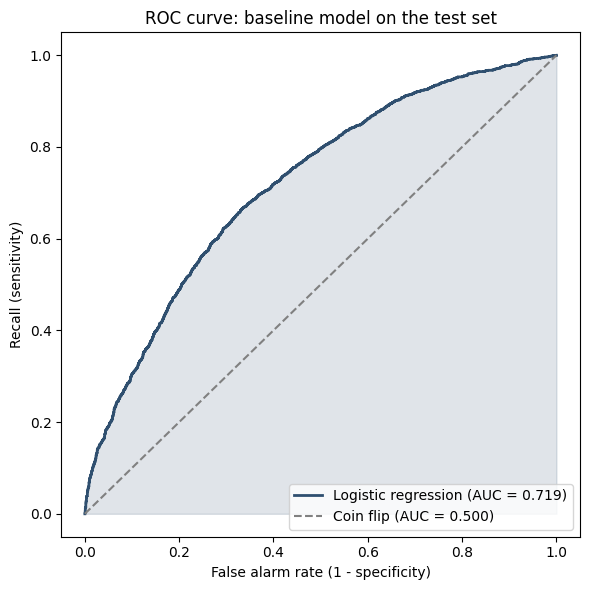

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from google.colab import files

fpr, tpr, _ = roc_curve(y_test, prob)
auc = roc_auc_score(y_test, prob)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="#2F4F6F", lw=2, label=f"Logistic regression (AUC = {auc:.3f})")
plt.fill_between(fpr, tpr, alpha=0.15, color="#2F4F6F")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Coin flip (AUC = 0.500)")
plt.xlabel("False alarm rate (1 - specificity)")
plt.ylabel("Recall (sensitivity)")
plt.title("ROC curve: baseline model on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fig_roc_baseline.png", dpi=200)
plt.show()
files.download("fig_roc_baseline.png")

### Testing on future reports (temporal hold-out)
Train on reports received 2015–2023, test on reports received 2024–2025, to check whether the model works on newer reports.

In [12]:
from sklearn.base import clone

# Separate names (…_future) so the random-split results above are not overwritten

df["receive_date"] = pd.to_datetime(df["receive_date"])
features = numeric + categorical + flags

train_future = df[df["receive_date"].dt.year <= 2023]
test_future = df[df["receive_date"].dt.year >= 2024]
print(f"Train (2015-2023): {len(train_future)} reports, {train_future['serious'].mean():.1%} serious")
print(f"Test  (2024-2025): {len(test_future)} reports, {test_future['serious'].mean():.1%} serious")

model_future = Pipeline([("prep", clone(prep)), ("model", LogisticRegression(max_iter=1000))])
model_future.fit(train_future[features], train_future["serious"])
pred_future = model_future.predict(test_future[features])
prob_future = model_future.predict_proba(test_future[features])[:, 1]
y_future = test_future["serious"]

print("\n=== Baseline tested on future reports (2024-2025) ===")
print(f"Accuracy {accuracy_score(y_future, pred_future):.3f} | Precision {precision_score(y_future, pred_future):.3f} | "
      f"Recall {recall_score(y_future, pred_future):.3f} | F1 {f1_score(y_future, pred_future):.3f} | "
      f"ROC-AUC {roc_auc_score(y_future, prob_future):.3f}")

Train (2015-2023): 21759 reports, 45.5% serious
Test  (2024-2025): 7460 reports, 57.7% serious

=== Baseline tested on future reports (2024-2025) ===
Accuracy 0.611 | Precision 0.717 | Recall 0.539 | F1 0.615 | ROC-AUC 0.686


## RQ4: Full Model Comparison
Random forest and XGBoost are tuned with randomized search under three-fold cross-validation (the same three folds used for the baseline) on the **same training set** as the baseline, then all three models are scored on the **same test set** (the same 5,844 reports). This makes the comparison fair.

In [13]:
# Install XGBoost and SHAP if they are missing (Colab usually has them already)
import importlib, subprocess, sys
for pkg in ["xgboost", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_curve
from xgboost import XGBClassifier
from google.colab import files

### Random forest (tuned)
Settings tried: number of trees, tree depth, minimum reports per leaf, and features per split. 6 combinations × 3 folds; this takes a few minutes.

In [15]:
rf_pipe = Pipeline([("prep", clone(prep)),
                    ("model", RandomForestClassifier(random_state=42, n_jobs=1))])
rf_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12, 16],
    "model__min_samples_leaf": [5, 20],
    "model__max_features": ["sqrt"],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_grid, n_iter=6, scoring="roc_auc",
                               cv=3, random_state=42, n_jobs=-1)
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_
print("Best random forest settings:", rf_search.best_params_)
print(f"Cross-validation AUC: {rf_search.best_score_:.3f}")

Best random forest settings: {'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 16}
Cross-validation AUC: 0.724


### XGBoost (tuned)
Settings tried: number of trees, learning rate, tree depth, row and column sampling, and minimum child weight. 10 combinations × 3 folds.

In [18]:
xgb_pipe = Pipeline([("prep", clone(prep)),
                     ("model", XGBClassifier(eval_metric="logloss", tree_method="hist",
                                             random_state=42, n_jobs=1))])
xgb_grid = {
    "model__n_estimators": [200, 400],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.7, 1.0],
    "model__min_child_weight": [1, 5],
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_grid, n_iter=10, scoring="roc_auc",
                                cv=3, random_state=42, n_jobs=-1)
xgb_search.fit(X_train, y_train)
xgb_best = xgb_search.best_estimator_
print("Best XGBoost settings:", xgb_search.best_params_)
print(f"Cross-validation AUC: {xgb_search.best_score_:.3f}")

Best XGBoost settings: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.7}
Cross-validation AUC: 0.723


### Test-set comparison of all three models
All models are scored on the same held-out test set at the default 0.5 threshold.

In [ ]:
models = {"Logistic regression": baseline, "Random forest": rf_best, "XGBoost": xgb_best}
cv_scores = {"Logistic regression": cv_auc.mean(),
             "Random forest": rf_search.best_score_,
             "XGBoost": xgb_search.best_score_}

def score(model, X_eval, y_eval):
    p = model.predict_proba(X_eval)[:, 1]
    yhat = (p >= 0.5).astype(int)
    return p, {"Accuracy": accuracy_score(y_eval, yhat), "Precision": precision_score(y_eval, yhat),
               "Recall": recall_score(y_eval, yhat), "F1": f1_score(y_eval, yhat),
               "ROC-AUC": roc_auc_score(y_eval, p)}

probs, rows = {}, []
for name, m in models.items():
    probs[name], metrics = score(m, X_test, y_test)
    rows.append({"Model": name, "CV ROC-AUC": cv_scores[name], **metrics})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
print(comparison)
comparison.to_csv("rq4_model_comparison.csv")

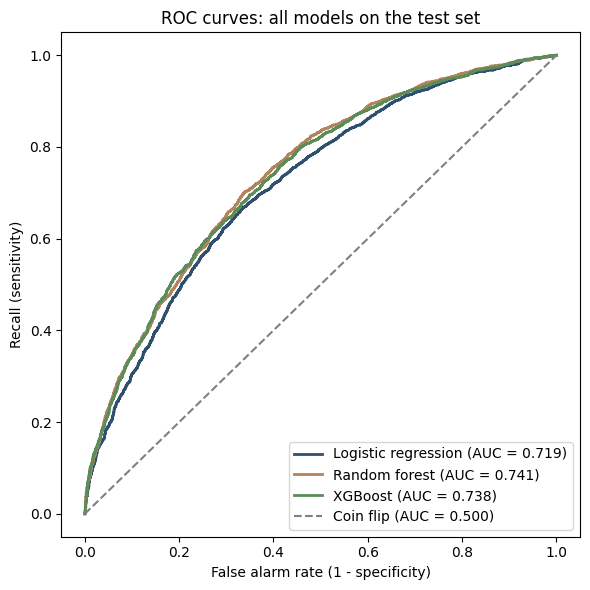

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# ROC curves of all three models on the same test set
plt.figure(figsize=(6, 6))
for (name, p), color in zip(probs.items(), ["#2F4F6F", "#B5835A", "#5B8C5A"]):
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, color=color, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Coin flip (AUC = 0.500)")
plt.xlabel("False alarm rate (1 - specificity)")
plt.ylabel("Recall (sensitivity)")
plt.title("ROC curves: all models on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("fig_roc_all_models.png", dpi=200)
plt.show()
files.download("fig_roc_all_models.png")

### DeLong test (answers RQ4)
H0: the best ML model's ROC-AUC is not higher than the baseline's. H1: it is higher (one-sided). The DeLong method compares two ROC-AUCs measured on the same test reports.

In [21]:
def _midrank(x):
    order = np.argsort(x); z = x[order]; n = len(x)
    ranks = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        ranks[i:j] = 0.5 * (i + j - 1)
        i = j
    out = np.empty(n); out[order] = ranks + 1
    return out

def delong_test(y_true, p_new, p_base):
    """Compare two correlated ROC-AUCs (DeLong et al., 1988; fast algorithm of Sun & Xu, 2014)."""
    y_true = np.asarray(y_true)
    order = np.argsort(-y_true, kind="mergesort")           # positives first
    m = int(y_true.sum())
    preds = np.vstack([np.asarray(p_new), np.asarray(p_base)])[:, order]
    n = preds.shape[1] - m
    tx = np.array([_midrank(r[:m]) for r in preds])
    ty = np.array([_midrank(r[m:]) for r in preds])
    tz = np.array([_midrank(r) for r in preds])
    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n
    v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    diff = aucs[0] - aucs[1]
    se = np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    z = diff / se
    return {"AUC new": aucs[0], "AUC baseline": aucs[1], "Difference": diff,
            "95% CI low": diff - 1.96 * se, "95% CI high": diff + 1.96 * se,
            "z": z, "p (one-sided)": norm.sf(z), "p (two-sided)": 2 * norm.sf(abs(z))}

best_name = max(["Random forest", "XGBoost"], key=lambda n: roc_auc_score(y_test, probs[n]))
print("Best ML model:", best_name)
delong_rows = []
for name in ["Random forest", "XGBoost"]:
    res = delong_test(y_test, probs[name], probs["Logistic regression"])
    delong_rows.append({"Comparison": f"{name} vs logistic regression", **res})
delong = pd.DataFrame(delong_rows).set_index("Comparison").round(4)
print(delong.T)
best_p = delong.loc[f"{best_name} vs logistic regression", "p (one-sided)"]
print("\nDecision for RQ4:", "Reject H0 (ML model is significantly better)" if best_p < 0.05
      else "Cannot reject H0 (no significant improvement)")
delong.to_csv("rq4_delong.csv")

Best ML model: Random forest
Comparison     Random forest vs logistic regression  \
AUC new                                      0.7409   
AUC baseline                                 0.7193   
Difference                                   0.0216   
95% CI low                                   0.0164   
95% CI high                                  0.0269   
z                                            8.0624   
p (one-sided)                                0.0000   
p (two-sided)                                0.0000   

Comparison     XGBoost vs logistic regression  
AUC new                                0.7376  
AUC baseline                           0.7193  
Difference                             0.0183  
95% CI low                             0.0132  
95% CI high                            0.0235  
z                                      6.9662  
p (one-sided)                          0.0000  
p (two-sided)                          0.0000  

Decision for RQ4: Reject H0 (ML model is s

### Testing all models on future reports (temporal hold-out)
Each model is re-trained with its tuned settings on reports received 2015–2023 and tested on reports received 2024–2025. ROC-AUC does not depend on the 0.5 threshold, so it is the fairest measure here.

In [22]:
Xf_train, yf_train = train_future[features], train_future["serious"]
Xf_test, yf_test = test_future[features], test_future["serious"]

future_probs, future_rows = {}, []
for name, m in models.items():
    m_future = clone(m).fit(Xf_train, yf_train)
    future_probs[name], metrics = score(m_future, Xf_test, yf_test)
    future_rows.append({"Model": name, **metrics})
future_comparison = pd.DataFrame(future_rows).set_index("Model").round(3)
print("=== All models tested on 2024-2025 reports ===")
print(future_comparison)

res = delong_test(yf_test, future_probs[best_name], future_probs["Logistic regression"])
print(f"\nDeLong on future reports, {best_name} vs logistic regression: "
      f"difference = {res['Difference']:.3f}, p (one-sided) = {res['p (one-sided)']:.4f}")
future_comparison.to_csv("rq4_future_comparison.csv")

=== All models tested on 2024-2025 reports ===
                     Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                           
Logistic regression     0.611      0.717   0.539  0.615    0.686
Random forest           0.632      0.720   0.594  0.651    0.699
XGBoost                 0.630      0.727   0.574  0.641    0.696

DeLong on future reports, Random forest vs logistic regression: difference = 0.014, p (one-sided) = 0.0000


### SHAP explanations of the best model
SHAP shows how much each feature pushes a report's predicted risk up or down. One-hot columns are added back together so each original variable (for example, drug) gets one importance score.

In [ ]:
import shap

best_model = models[best_name]
prep_fitted = best_model.named_steps["prep"]
tree_model = best_model.named_steps["model"]

sample = X_test.sample(n=min(1000, len(X_test)), random_state=42)
X_sample = prep_fitted.transform(sample)
X_sample = X_sample.toarray() if hasattr(X_sample, "toarray") else np.asarray(X_sample)
names = prep_fitted.get_feature_names_out()

explainer = shap.TreeExplainer(tree_model)
sv = explainer.shap_values(X_sample)
if isinstance(sv, list):                 # some versions return one array per class
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:                         # (rows, features, classes)
    sv = sv[:, :, 1]

def original_variable(name):
    group, col = name.split("__", 1)
    if group == "cat":
        return next(c for c in categorical if col.startswith(c + "_") or col == c)
    if col.startswith("missingindicator_"):
        return col.replace("missingindicator_", "")
    return col

importance = (pd.DataFrame({"variable": [original_variable(n) for n in names],
                            "mean_abs_shap": np.abs(sv).mean(axis=0)})
              .groupby("variable")["mean_abs_shap"].sum().sort_values(ascending=False))
print("Mean |SHAP| by original variable (higher = more influence):")
print(importance.round(4))
importance.to_csv("rq4_shap_importance.csv")

plt.figure(figsize=(7, 5))
importance.sort_values().plot.barh(color="#2F4F6F")
plt.xlabel("Mean |SHAP value| (average change in predicted probability of serious)")
plt.tight_layout()
plt.savefig("fig_shap_importance.png", dpi=200)
plt.show()

shap.summary_plot(sv, X_sample, feature_names=names, max_display=15, show=False)
plt.tight_layout()
plt.savefig("fig_shap_summary.png", dpi=200, bbox_inches="tight")
plt.show()
files.download("fig_shap_importance.png")
files.download("fig_shap_summary.png")

## RQ3: Assumption Checks
Multicollinearity (variance inflation factors), linearity of age and weight on the log-odds (spline comparison), and the ρ² used in the sample size calculation.

In [24]:
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2 as chi2_dist

rq3 = df.dropna(subset=["age_years", "weight_kg"]).copy()
design = pd.get_dummies(rq3[["age_years", "weight_kg", "species", "drug"]],
                        columns=["species", "drug"], drop_first=True).astype(float)
design.insert(0, "const", 1.0)
vif = pd.Series([variance_inflation_factor(design.values, i) for i in range(1, design.shape[1])],
                index=design.columns[1:]).round(2)
print("Variance inflation factors (below 5 = acceptable):")
print(vif)

base_formula = "C(species, Treatment('Dog')) + C(drug, Treatment('Carprofen'))"
linear = smf.logit(f"serious ~ age_years + weight_kg + {base_formula}", data=rq3).fit(disp=0)
spline = smf.logit(f"serious ~ cr(age_years, df=4) + cr(weight_kg, df=4) + {base_formula}",
                   data=rq3).fit(disp=0)
lr_stat = 2 * (spline.llf - linear.llf)
lr_df = spline.df_model - linear.df_model
print(f"\nLinearity check: AIC linear = {linear.aic:.1f}, AIC spline = {spline.aic:.1f}")
print(f"Likelihood-ratio test: chi2({lr_df:.0f}) = {lr_stat:.2f}, p = {chi2_dist.sf(lr_stat, lr_df):.4f}")

for v in ["age_years", "weight_kg"]:
    others = [c for c in design.columns if c not in ("const", v)]
    r2 = smf.ols(f"{v} ~ " + " + ".join(f"Q('{c}')" for c in others), data=design).fit().rsquared
    print(f"rho^2 for {v} (explained by the other predictors): {r2:.2f}")

Variance inflation factors (below 5 = acceptable):
age_years           1.10
weight_kg           1.29
species_Dog         3.54
drug_Deracoxib      1.07
drug_Firocoxib      1.07
drug_Grapiprant     1.23
drug_Meloxicam      1.39
drug_Robenacoxib    3.53
dtype: float64


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



Linearity check: AIC linear = 35879.0, AIC spline = 35874.2
Likelihood-ratio test: chi2(4) = 12.75, p = 0.0126
rho^2 for age_years (explained by the other predictors): 0.09
rho^2 for weight_kg (explained by the other predictors): 0.23


## Sensitivity Analysis: Veterinarian Reports Only
Repeats RQ1–RQ3 using only reports submitted by veterinarians, to check whether owner reporting changes the conclusions.

In [25]:
vet = df[df["reporter"].astype(str).str.contains("Veterinarian", case=False)]
print(f"Veterinarian-submitted reports: {len(vet)} of {len(df)} ({len(vet)/len(df):.1%})")

def two_group_test(data, group_col, g1, g2):
    t = pd.crosstab(data[group_col], data["serious"]).loc[[g1, g2]]
    c2, p_val, _, _ = chi2_contingency(t, correction=False)
    n1, n2 = t.loc[g1].sum(), t.loc[g2].sum()
    p1, p2 = t.loc[g1, 1] / n1, t.loc[g2, 1] / n2
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return {"n": n1 + n2, f"{g1} %": 100 * p1, f"{g2} %": 100 * p2, "Difference": 100 * (p1 - p2),
            "CI low": 100 * (p1 - p2 - 1.96 * se), "CI high": 100 * (p1 - p2 + 1.96 * se),
            "chi2": c2, "p": p_val, "phi": np.sqrt(c2 / (n1 + n2))}

rq1_vet = two_group_test(vet[vet["drug"] == "Meloxicam"], "species", "Cat", "Dog")
rq2_vet = two_group_test(vet[(vet["species"] == "Dog") & vet["drug"].isin(["Grapiprant", "Carprofen"])],
                         "drug", "Grapiprant", "Carprofen")
print("\nRQ1 (vet only):", {k: round(float(v), 4) for k, v in rq1_vet.items()})
print("RQ2 (vet only):", {k: round(float(v), 4) for k, v in rq2_vet.items()})

vet3 = vet.dropna(subset=["age_years", "weight_kg"])
m_vet = smf.logit("serious ~ age_years + weight_kg + C(species, Treatment('Dog')) "
                  "+ C(drug, Treatment('Carprofen'))", data=vet3).fit(disp=0)
ci = m_vet.conf_int()
print(f"\nRQ3 (vet only), n = {len(vet3)}")
for v in ["age_years", "weight_kg"]:
    print(f"  {v}: OR = {np.exp(m_vet.params[v]):.4f} "
          f"(95% CI {np.exp(ci.loc[v, 0]):.4f} to {np.exp(ci.loc[v, 1]):.4f}), p = {m_vet.pvalues[v]:.4f}")

Veterinarian-submitted reports: 13537 of 29219 (46.3%)

RQ1 (vet only): {'n': 1626.0, 'Cat %': 63.6364, 'Dog %': 61.1915, 'Difference': 2.4449, 'CI low': -2.7968, 'CI high': 7.6865, 'chi2': 0.8258, 'p': 0.3635, 'phi': 0.0225}
RQ2 (vet only): {'n': 8878.0, 'Grapiprant %': 34.6685, 'Carprofen %': 56.9325, 'Difference': -22.264, 'CI low': -24.3908, 'CI high': -20.1372, 'chi2': 391.9829, 'p': 0.0, 'phi': 0.2101}

RQ3 (vet only), n = 12588
  age_years: OR = 1.0046 (95% CI 0.9960 to 1.0132), p = 0.3001
  weight_kg: OR = 1.0020 (95% CI 0.9993 to 1.0047), p = 0.1467


## Saving the Results
All result tables are saved as CSV files for the final report and the GitHub repository.

In [26]:
for f in ["rq4_model_comparison.csv", "rq4_delong.csv", "rq4_future_comparison.csv",
          "rq4_shap_importance.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>